# Store Sales EDA 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## 1. train.csv

In [ ]:
train = pd.read_csv('./train_store.csv', compression='zip', parse_dates=['date'])
print(train.shape)
train.head()

(3000888, 6)
(3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [10]:
train.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [11]:
train.nunique()

id             3000888
date              1684
store_nbr           54
family              33
sales           379610
onpromotion        362
dtype: int64

### Date Check

Check every store has the same dates and check which dates are missing if there is any

In [12]:
date_counts = train.groupby('store_nbr')['date'].nunique()
print(date_counts.describe())
print("Every store has the same number of date:", date_counts.nunique() == 1)

# compare the dates
full_range = pd.date_range(train['date'].min(), train['date'].max())
missing_by_store = {}
for s, g in train.groupby('store_nbr'):
    missing = set(full_range) - set(g['date'])
    if missing:
        missing_by_store[s] = sorted(missing)

if missing_by_store:
    print(f"number of stores with missing date: {len(missing_by_store)} / {train['store_nbr'].nunique()}")
    first_store = list(missing_by_store)[0]
    print(f"Missing date of store{first_store}:", missing_by_store[first_store][:5])
else:
    print("Every store has the same date sets")

count      54.0
mean     1684.0
std         0.0
min      1684.0
25%      1684.0
50%      1684.0
75%      1684.0
max      1684.0
Name: date, dtype: float64
Every store has the same number of date: True
number of stores with missing date: 54 / 54
Missing date of store1: [Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


>Every store has the same number of dates (1684 days) and every Christmas (25/12) is the missing date

Store VS Sales

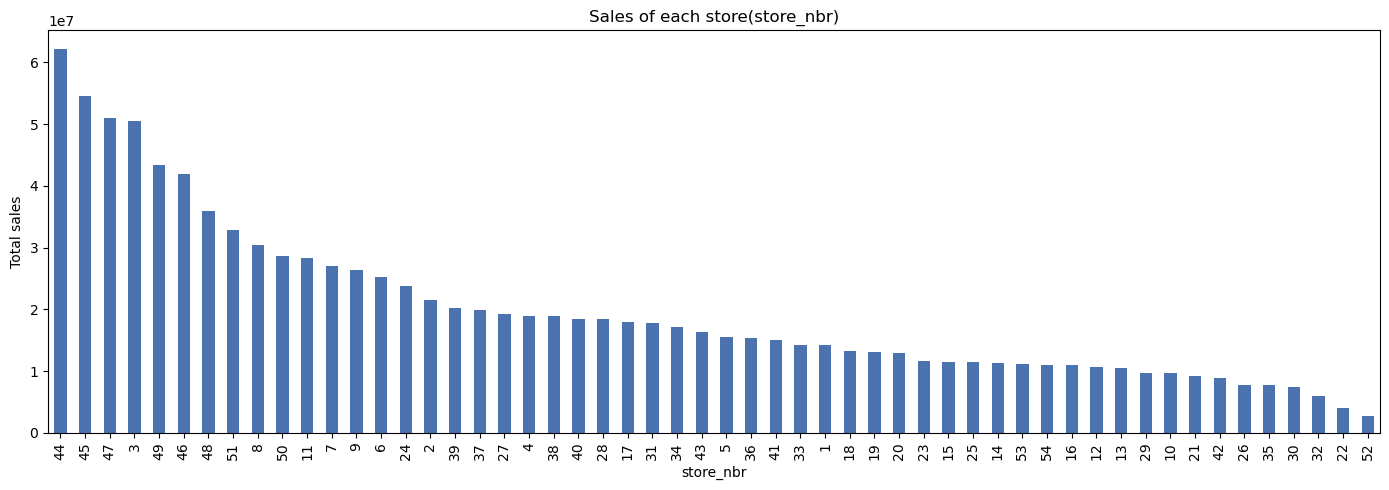

In [13]:
sales_by_store = train.groupby('store_nbr')['sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 5))
sales_by_store.plot(kind='bar', color='#4C72B0')
plt.title('Sales of each store(store_nbr)')
plt.xlabel('store_nbr')
plt.ylabel('Total sales')
plt.tight_layout()
plt.show()

### Dates VS Sales

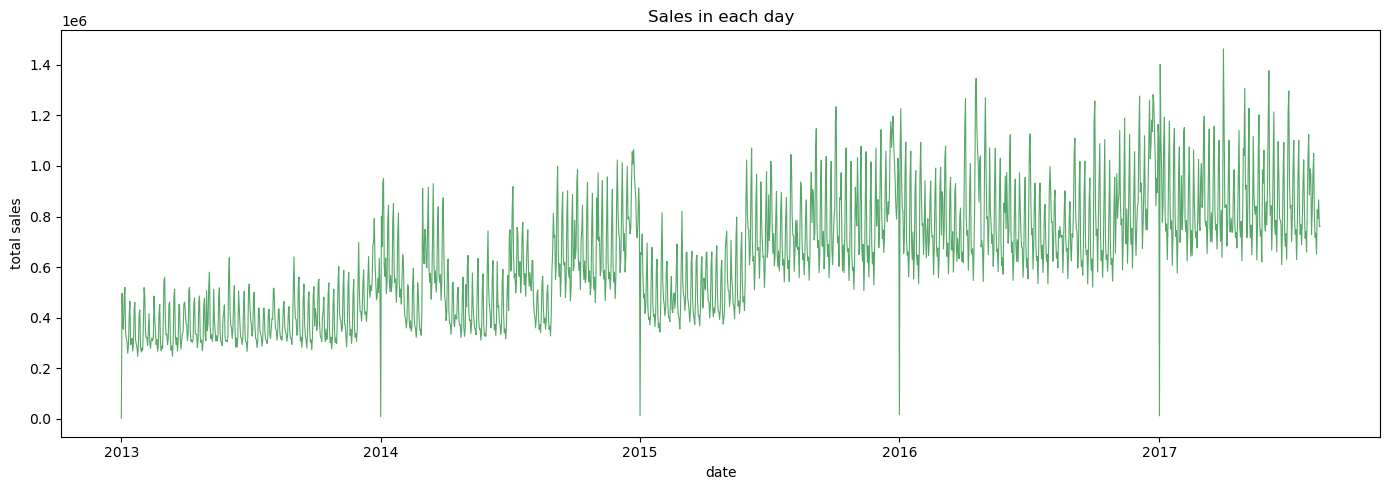

In [14]:
sales_by_date = train.groupby('date')['sales'].sum()

plt.figure(figsize=(14, 5))
plt.plot(sales_by_date.index, sales_by_date.values, color='#55A868', linewidth=0.8)
plt.title('Sales in each day')
plt.xlabel('date')
plt.ylabel('total sales')
plt.tight_layout()
plt.show()

### On promotion VS Dates

Only take 50,000 as it has 3,000,000 rows

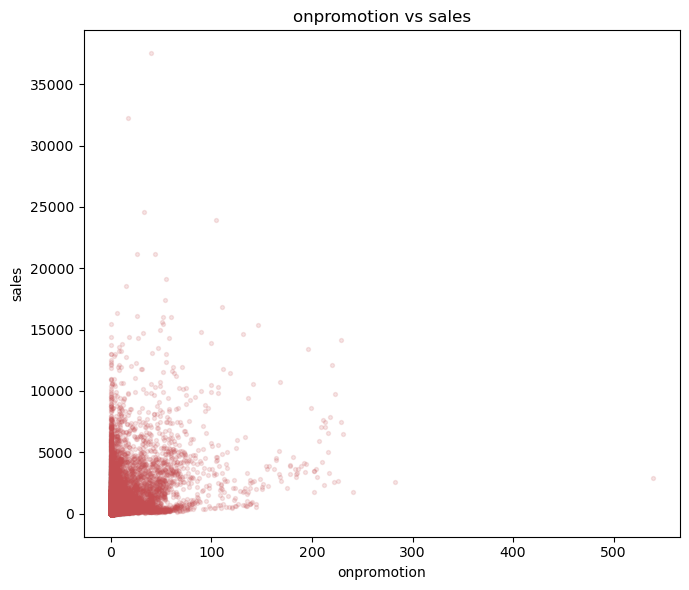

corr(onpromotion, sales) = 0.4279


In [15]:
sample = train.sample(n=50000, random_state=42)

plt.figure(figsize=(7, 6))
plt.scatter(sample['onpromotion'], sample['sales'], alpha=0.15, s=8, color='#C44E52')
plt.title('onpromotion vs sales')
plt.xlabel('onpromotion')
plt.ylabel('sales')
plt.tight_layout()
plt.show()

print("corr(onpromotion, sales) =", train['onpromotion'].corr(train['sales']).round(4))

## 2. stores.csv

In [17]:
stores = pd.read_csv('./stores_stores.csv')
stores.head()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [18]:
stores.isnull().sum()

store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

Number of stores in each city

city
Quito            18
Guayaquil         8
Cuenca            3
Santo Domingo     3
Manta             2
Latacunga         2
Machala           2
Ambato            2
Quevedo           1
Esmeraldas        1
Loja              1
Libertad          1
Playas            1
Daule             1
Babahoyo          1
Salinas           1
Puyo              1
Guaranda          1
Ibarra            1
Riobamba          1
Cayambe           1
El Carmen         1
Name: count, dtype: int64


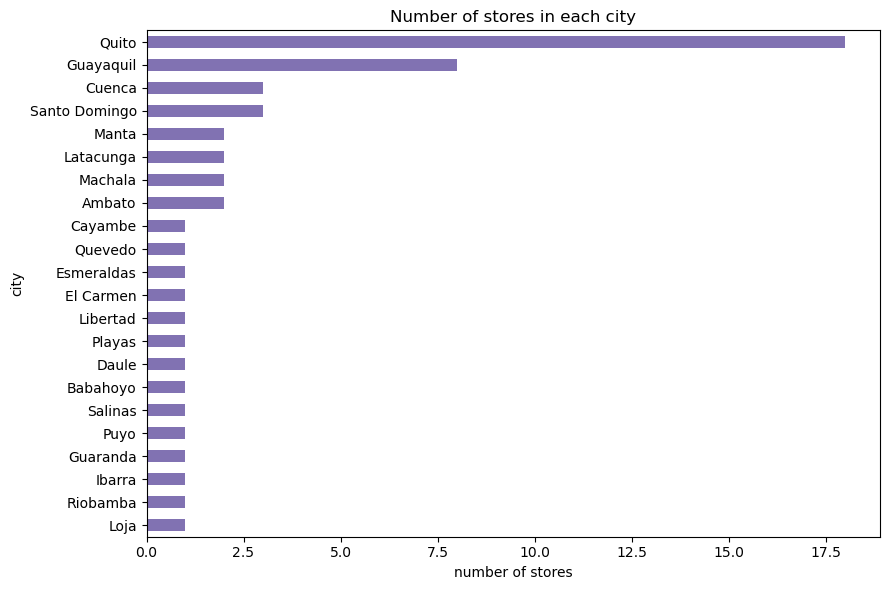

In [19]:
city_counts = stores['city'].value_counts()
print(city_counts)

plt.figure(figsize=(9, 6))
city_counts.sort_values().plot(kind='barh', color='#8172B2')
plt.title('Number of stores in each city')
plt.xlabel('number of stores')
plt.tight_layout()
plt.show()

### Number of stores in each state

state
Pichincha                         19
Guayas                            11
Santo Domingo de los Tsachilas     3
Azuay                              3
Manabi                             3
Cotopaxi                           2
Tungurahua                         2
Los Rios                           2
El Oro                             2
Chimborazo                         1
Imbabura                           1
Bolivar                            1
Pastaza                            1
Santa Elena                        1
Loja                               1
Esmeraldas                         1
Name: count, dtype: int64


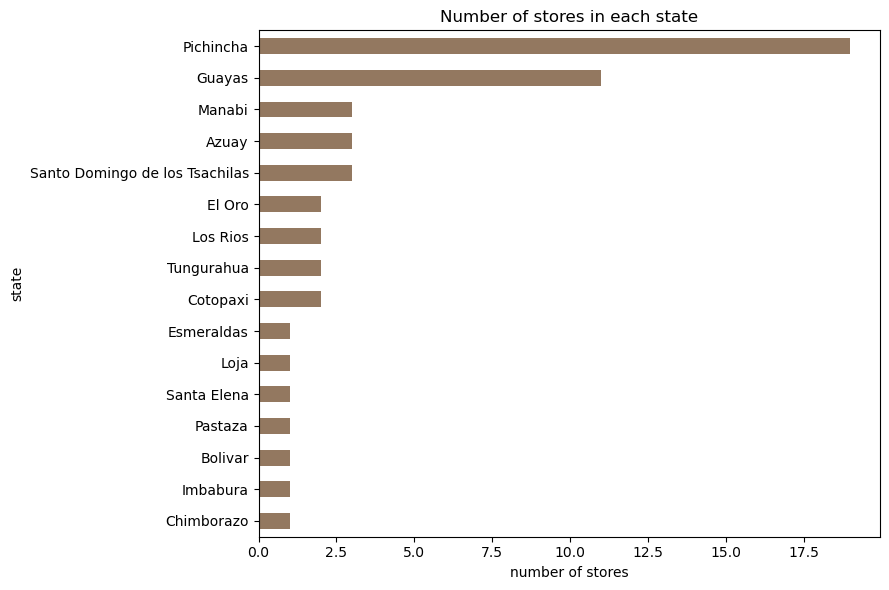

In [20]:
state_counts = stores['state'].value_counts()
print(state_counts)

plt.figure(figsize=(9, 6))
state_counts.sort_values().plot(kind='barh', color='#937860')
plt.title('Number of stores in each state')
plt.xlabel('number of stores')
plt.tight_layout()
plt.show()

## 3. oil.csv 

In [21]:
oil = pd.read_csv('./oil.csv', parse_dates=['date'])
oil.isnull().sum()

date           0
dcoilwtico    43
dtype: int64

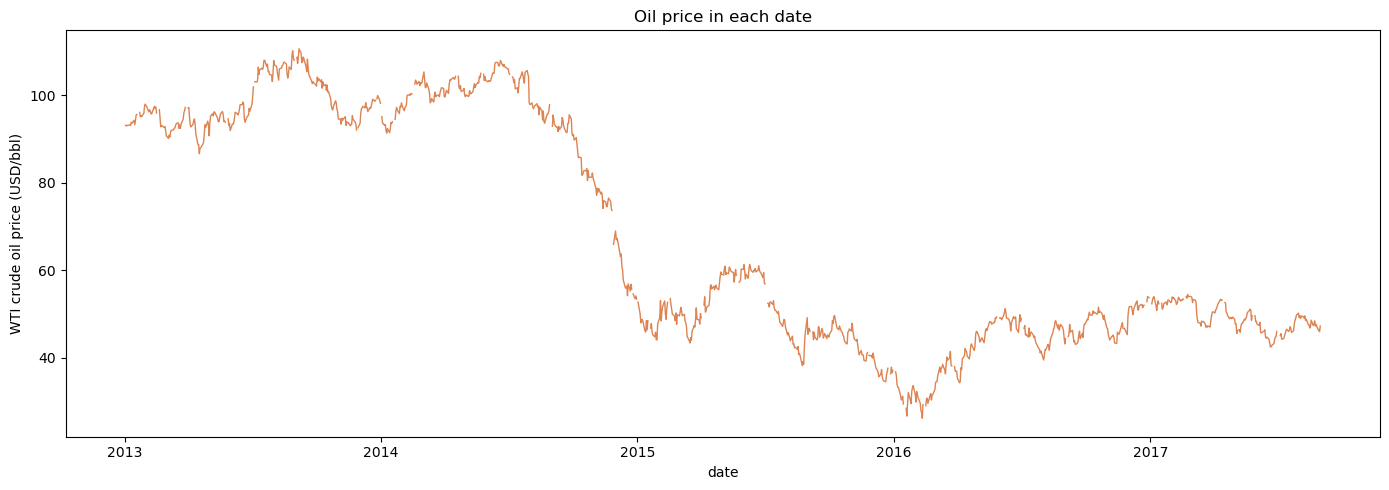

In [22]:
plt.figure(figsize=(14, 5))
plt.plot(oil['date'], oil['dcoilwtico'], color='#DD8452', linewidth=1)
plt.title('Oil price in each date')
plt.xlabel('date')
plt.ylabel('WTI crude oil price (USD/bbl)')
plt.tight_layout()
plt.show()

## 4. transactions.csv 

In [25]:
transactions = pd.read_csv('./transactions.csv.zip', compression='zip' , parse_dates=['date'])
transactions.head()

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [26]:
transactions.isnull().sum()

date            0
store_nbr       0
transactions    0
dtype: int64

### Total number of transaction in each store

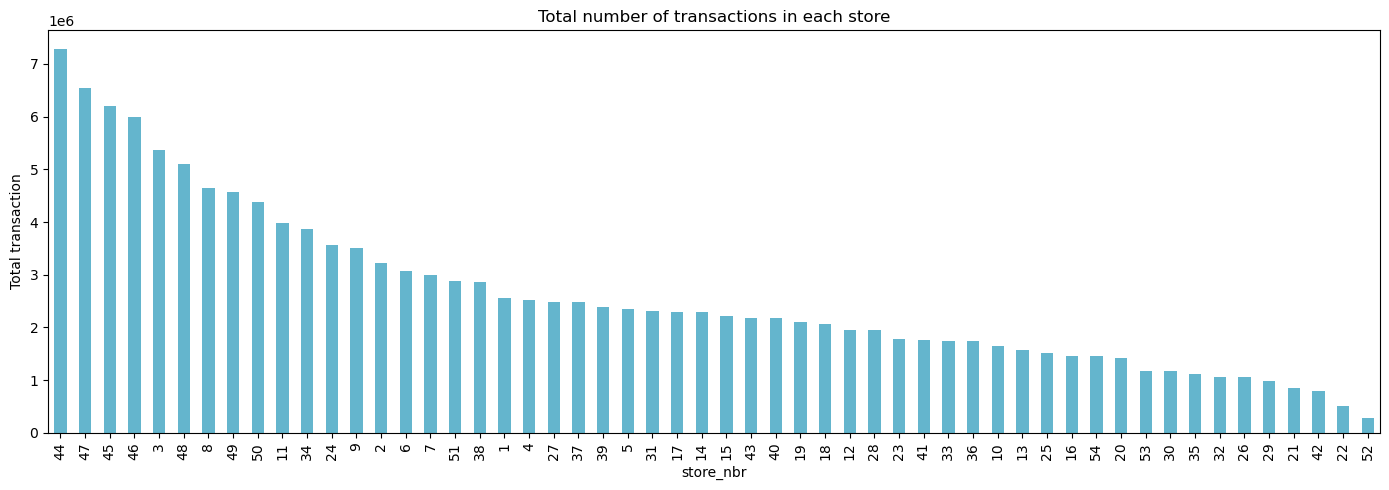

In [27]:
tx_by_store = transactions.groupby('store_nbr')['transactions'].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 5))
tx_by_store.plot(kind='bar', color='#64B5CD')
plt.title('Total number of transactions in each store')
plt.xlabel('store_nbr')
plt.ylabel('Total transaction')
plt.tight_layout()
plt.show()

### Transaction in each day

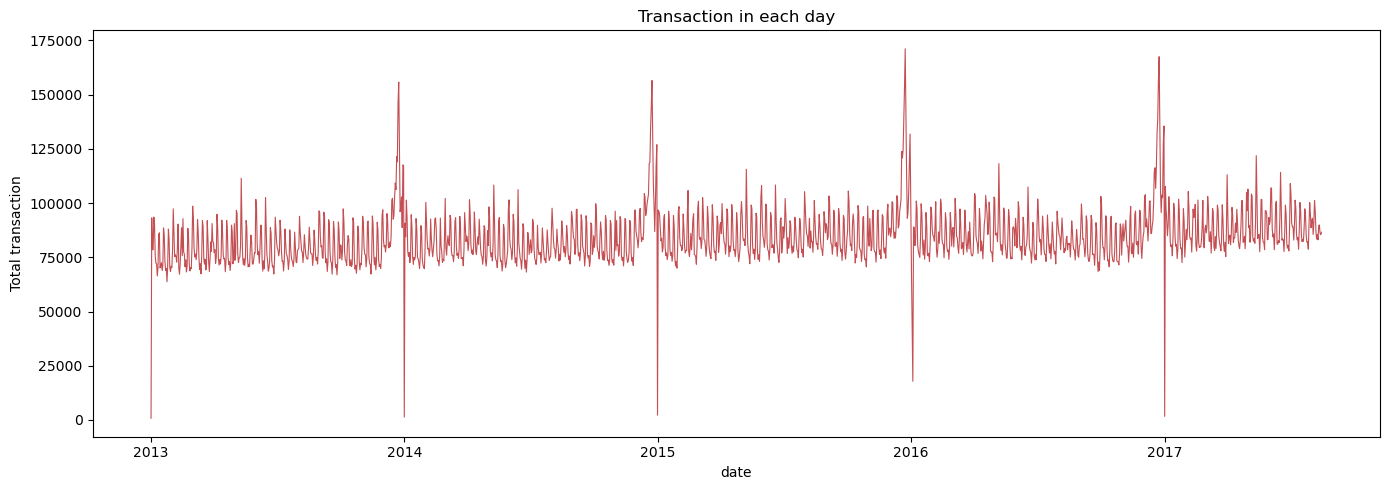

In [28]:
tx_by_date = transactions.groupby('date')['transactions'].sum()

plt.figure(figsize=(14, 5))
plt.plot(tx_by_date.index, tx_by_date.values, color='#C44E52', linewidth=0.8)
plt.title('Transaction in each day')
plt.xlabel('date')
plt.ylabel('Total transaction')
plt.tight_layout()
plt.show()

## 5. Missing dates in each dataset

In [29]:
train_dates = set(train['date'].unique())

# oil.csv
oil_dates = set(oil['date'].unique())
missing_in_oil = sorted(train_dates - oil_dates)
extra_in_oil = sorted(oil_dates - train_dates)
print("=== oil.csv ===")
print(f"Exist in train, but not in oil: {len(missing_in_oil)}")
print(missing_in_oil[:10], "...")
print(f"Exist in oil but not in train: {len(extra_in_oil)}")
print(extra_in_oil[:10])

# transactions.csv
tx_dates = set(transactions['date'].unique())
missing_in_tx = sorted(train_dates - tx_dates)
extra_in_tx = sorted(tx_dates - train_dates)
print("\n=== transactions.csv ===")
print(f"Exist in train but not in transactions: {len(missing_in_tx)}")
print(missing_in_tx[:10], "...")
print(f"Exist transactions but not in train: {len(extra_in_tx)}")
print(extra_in_tx[:10])

# missing dates in transaction per each store number
print("\n=== Checking for each stores ===")
n_stores = train['store_nbr'].nunique()
tx_store_count = transactions.groupby('date')['store_nbr'].nunique()
incomplete_dates = tx_store_count[tx_store_count < n_stores]
print(f"Dates that do not have all ({n_stores}) stores transaction: {len(incomplete_dates)}")
incomplete_dates.head(10)

=== oil.csv ===
Exist in train, but not in oil: 481
[Timestamp('2013-01-05 00:00:00'), Timestamp('2013-01-06 00:00:00'), Timestamp('2013-01-12 00:00:00'), Timestamp('2013-01-13 00:00:00'), Timestamp('2013-01-19 00:00:00'), Timestamp('2013-01-20 00:00:00'), Timestamp('2013-01-26 00:00:00'), Timestamp('2013-01-27 00:00:00'), Timestamp('2013-02-02 00:00:00'), Timestamp('2013-02-03 00:00:00')] ...
Exist in oil but not in train: 15
[Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2017-08-16 00:00:00'), Timestamp('2017-08-17 00:00:00'), Timestamp('2017-08-18 00:00:00'), Timestamp('2017-08-21 00:00:00'), Timestamp('2017-08-22 00:00:00'), Timestamp('2017-08-23 00:00:00'), Timestamp('2017-08-24 00:00:00')]

=== transactions.csv ===
Exist in train but not in transactions: 2
[Timestamp('2016-01-01 00:00:00'), Timestamp('2016-01-03 00:00:00')] ...
Exist transactions but not in train: 0
[]

=== Checking for each stores ===
Dates that 

date
2013-01-01     1
2013-01-02    46
2013-01-03    46
2013-01-04    46
2013-01-05    46
2013-01-06    46
2013-01-07    46
2013-01-08    46
2013-01-09    46
2013-01-10    46
Name: store_nbr, dtype: int64

> Oil data is missing quite a lot. Should we include it?
> Will we assume stores without transaction as 0?

## 6. Joining data to train.csv (main dataset file)

### city, states from stores.csv

In [30]:
train = train.merge(stores[['store_nbr', 'city', 'state']], on='store_nbr', how='left')
train[['store_nbr', 'city', 'state']].drop_duplicates().head()

,store_nbr,city,state
0,1,Quito,Pichincha
33,10,Quito,Pichincha
66,11,Cayambe,Pichincha
99,12,Latacunga,Cotopaxi
132,13,Latacunga,Cotopaxi


### oil price from oil.csv

In [31]:
train = train.merge(oil, on='date', how='left')
train = train.rename(columns={'dcoilwtico': 'oil_price'})

print("missing number of oil_price:", train['oil_price'].isnull().sum())
train[['date', 'oil_price']].head()

missing number of oil_price: 928422


,date,oil_price
0,2013-01-01,NaN
1,2013-01-01,NaN
2,2013-01-01,NaN
3,2013-01-01,NaN
4,2013-01-01,NaN


### Transaction based on date and store number

In [32]:
train = train.merge(transactions, on=['date', 'store_nbr'], how='left')

print("number of missing transactions:", train['transactions'].isnull().sum())
print("Final train shape:", train.shape)
train[['date', 'store_nbr', 'transactions']].head()

number of missing transactions: 245784
Final train shape: (3000888, 10)


,date,store_nbr,transactions
0,2013-01-01,1,NaN
1,2013-01-01,1,NaN
2,2013-01-01,1,NaN
3,2013-01-01,1,NaN
4,2013-01-01,1,NaN


### Adding holidays and type

Based on `date`, `city`, `state`of each row, check holidays_events.csv. If there is a holiday, `holiday=True`, else mark it `False`.

Mathcing criteria:

- `National` → `date` matches, `holiday=True`
- `Regional` → `date` + `state`(locale_name) matches, `holiday=True`
- `Local` → `date` + `city`(locale_name) matches, `holiday=True`

if there is multiple holidays in a day or region, the type will be continued with coma(,).

In [33]:
holidays = pd.read_csv('./holidays_events.csv', parse_dates=['date'])
holidays['locale'].value_counts()

locale
National    174
Local       152
Regional     24
Name: count, dtype: int64

In [34]:
national_map = (holidays[holidays['locale'] == 'National']
                 .groupby('date')['type']
                 .apply(lambda x: ','.join(sorted(set(x))))
                 .reset_index().rename(columns={'type': 'type_national'}))

regional_map = (holidays[holidays['locale'] == 'Regional']
                 .rename(columns={'locale_name': 'state'})
                 .groupby(['date', 'state'])['type']
                 .apply(lambda x: ','.join(sorted(set(x))))
                 .reset_index().rename(columns={'type': 'type_regional'}))

local_map = (holidays[holidays['locale'] == 'Local']
              .rename(columns={'locale_name': 'city'})
              .groupby(['date', 'city'])['type']
              .apply(lambda x: ','.join(sorted(set(x))))
              .reset_index().rename(columns={'type': 'type_local'}))

print("national_map:", national_map.shape, " regional_map:", regional_map.shape, " local_map:", local_map.shape)

national_map: (168, 2)  regional_map: (24, 3)  local_map: (151, 3)


In [35]:
before = len(train)
train = train.merge(national_map, on='date', how='left')
train = train.merge(regional_map, on=['date', 'state'], how='left')
train = train.merge(local_map, on=['date', 'city'], how='left')

In [36]:
def _join_types(df, cols):
    """merge national/regional/local type into one type column"""
     
    parts = [df[c].fillna('').astype(str) for c in cols]
    s = parts[0]
    for p in parts[1:]:
        sep = pd.Series(np.where((s == '') | (p == ''), '', ','), index=df.index)
        s = s + sep + p
    return s.replace('', np.nan)

train['type'] = _join_types(train, ['type_national', 'type_regional', 'type_local'])
train['holiday'] = train['type'].notna()
train = train.drop(columns=['type_national', 'type_regional', 'type_local'])

print("holiday=True ratio:", train['holiday'].mean().round(4))
train.loc[train['holiday'], 'type'].value_counts().head(10)

holiday=True ratio: 0.0892


type
Event                  94182
Holiday                90915
Additional             51414
Transfer               12573
Work Day                8844
Bridge                  3564
Event,Holiday           2046
Additional,Bridge       1782
Additional,Event        1782
Additional,Transfer      264
Name: count, dtype: int64

## 7. Some sales related EDA
### Best slaed family(category)

In [37]:
sales_by_family = train.groupby('family')['sales'].sum().sort_values(ascending=False)
print(sales_by_family.head(10))
print("1st:", sales_by_family.idxmax())

family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64
1st: GROCERY I


### Best saled family per store

In [38]:
sales_by_store_family = train.groupby(['store_nbr', 'family'])['sales'].sum()

top_family_per_store = sales_by_store_family.groupby('store_nbr').idxmax().apply(lambda x: x[1])
top_family_per_store.name = 'top_family'
top_sales_per_store = sales_by_store_family.groupby('store_nbr').max()

result = pd.concat([top_family_per_store, top_sales_per_store.rename('sales')], axis=1)
print(result)

print(top_family_per_store.value_counts())

          top_family         sales
store_nbr                         
1          GROCERY I  3.743823e+06
2          GROCERY I  6.591704e+06
3          GROCERY I  1.297047e+07
4          GROCERY I  5.636344e+06
5          GROCERY I  5.262682e+06
6          GROCERY I  7.806646e+06
7          GROCERY I  6.247974e+06
8          GROCERY I  7.909966e+06
9          GROCERY I  1.035310e+07
10         GROCERY I  4.126220e+06
11         GROCERY I  1.104495e+07
12         GROCERY I  4.208524e+06
13         GROCERY I  4.570081e+06
14         GROCERY I  4.463306e+06
15         GROCERY I  4.578222e+06
16         GROCERY I  4.307272e+06
17         GROCERY I  6.453635e+06
18         GROCERY I  4.138689e+06
19         GROCERY I  5.085658e+06
20         GROCERY I  4.785024e+06
21         GROCERY I  3.162816e+06
22         GROCERY I  1.570262e+06
23         GROCERY I  3.339714e+06
24         GROCERY I  6.343142e+06
25         BEVERAGES  2.963941e+06
26         GROCERY I  2.720338e+06
27         GROCERY I

### Montly sales change per family

Calculated by std/mean
The bigger it is, it changes more.

family
BOOKS                         2.973183
SCHOOL AND OFFICE SUPPLIES    1.839320
BABY CARE                     1.072323
MAGAZINES                     1.010457
FROZEN FOODS                  0.892863
PET SUPPLIES                  0.866916
PLAYERS AND ELECTRONICS       0.847188
CELEBRATION                   0.832648
LADIESWEAR                    0.826635
PRODUCE                       0.821178
dtype: float64


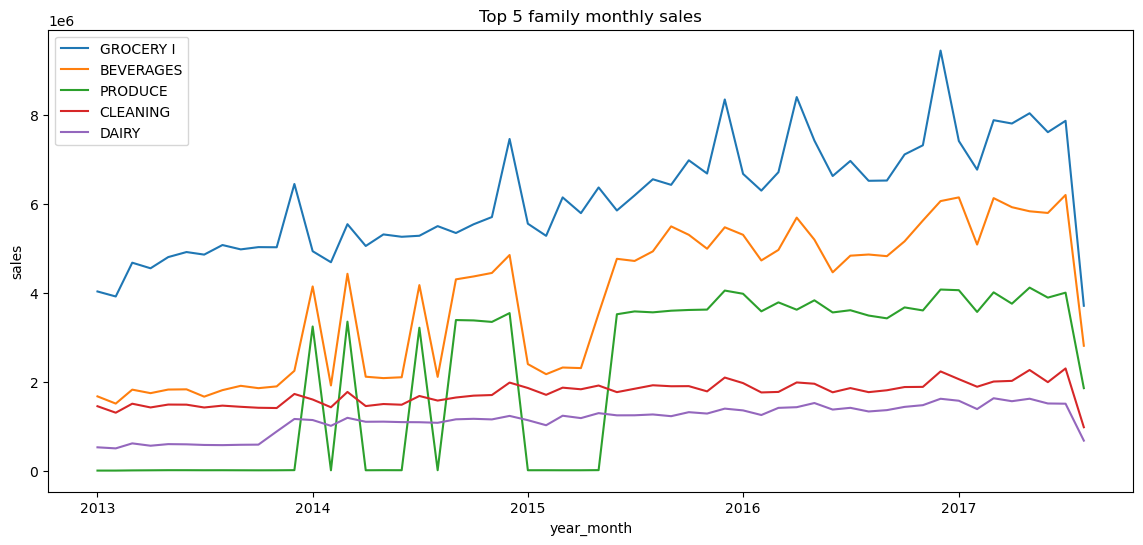

In [39]:
train['year_month'] = train['date'].dt.to_period('M')
monthly_family_sales = train.groupby(['family', 'year_month'])['sales'].sum().unstack('family')


cv = (monthly_family_sales.std() / monthly_family_sales.mean()).sort_values(ascending=False)
print(cv.head(10))

# Top 5 family that has big change 
top5 = sales_by_family.head(5).index
plt.figure(figsize=(14,6))
for f in top5:
    plt.plot(monthly_family_sales.index.to_timestamp(), monthly_family_sales[f], label=f)
plt.legend(); plt.title('Top 5 family monthly sales'); plt.xlabel('year_month'); plt.ylabel('sales')
plt.show()